In [9]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

def load_audio(file_path, sr=22050):
    """Q2.1: Loads audio, returns signal and sample rate."""
    y, sr = librosa.load(file_path, sr=sr)
    duration = librosa.get_duration(y=y, sr=sr)
    print(f"Loaded {file_path} | SR: {sr} | Duration: {duration:.2f}s")
    return y, sr


In [ ]:
def preprocess_audio(y, top_db=20):
    """Q2.2 & Q2.3: Normalization and Silence Removal."""
    y_norm = librosa.util.normalize(y)
    y_trimmed, _ = librosa.effects.trim(y_norm, top_db=top_db)
    
    return y_trimmed

In [ ]:
def extract_features(y, sr, n_mfcc=13):
    """Q3.1 & Q3.2: Extract MFCCs, Deltas, Spectral features."""

    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)

    delta_mfcc = librosa.feature.delta(mfccs)
    delta2_mfcc = librosa.feature.delta(mfccs, order=2)
    
    spec_cent = librosa.feature.spectral_centroid(y=y, sr=sr)
    spec_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    
    features = np.vstack([mfccs, delta_mfcc, delta2_mfcc, spec_cent, spec_bw])
    
    return features

In [ ]:
def aggregate_features(features):
    """Q3.4: Aggregation (Mean + Std Dev)."""

    mean = np.mean(features, axis=1)
    std = np.std(features, axis=1)

    global_feature = np.concatenate([mean, std])
    return global_feature

In [ ]:
try:
    y, sr = load_audio(librosa.ex('trumpet'))
    
    y_clean = preprocess_audio(y)
    

    frames = librosa.util.frame(y_clean, frame_length=int(sr*0.025), hop_length=int(sr*0.0125))
    
    feats = extract_features(y_clean, sr)
    
    final_vector = aggregate_features(feats)
    
    print(f"Feature Matrix Shape: {feats.shape}")
    print(f"Final Vector Shape: {final_vector.shape}")
    
except Exception as e:
    print(f"Error: {e}")

Loaded /root/.cache/librosa/sorohanro_-_solo-trumpet-06.ogg | SR: 22050 | Duration: 5.33s
Feature Matrix Shape: (41, 132)
Final Vector Shape: (82,)


In [ ]:
from sklearn.model_selection import train_test_split

np.random.seed(42)
X_dummy = np.random.rand(100, 86) 
y_dummy = np.random.randint(0, 5, 100) 


X_train, X_test, y_train, y_test = train_test_split(X_dummy, y_dummy, test_size=0.2, random_state=42)

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='rbf', C=1.0, probability=True))
])

# Train
pipeline.fit(X_train, y_train)

# Predict
y_pred = pipeline.predict(X_test)

In [16]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

acc = accuracy_score(y_test, y_pred)

In [ ]:
print(f"Accuracy: {acc:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.25

Classification Report:
               precision    recall  f1-score   support

           1       0.28      0.83      0.42         6
           2       0.00      0.00      0.00         5
           3       0.00      0.00      0.00         5
           4       0.00      0.00      0.00         4

    accuracy                           0.25        20
   macro avg       0.07      0.21      0.10        20
weighted avg       0.08      0.25      0.12        20



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

pipeline_forest = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Train
pipeline_forest.fit(X_train, y_train)

# Predict
y_pred = pipeline_forest.predict(X_test)

In [21]:
print(f"Accuracy: {acc:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.25

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.45      0.83      0.59         6
           2       0.33      0.40      0.36         5
           3       0.00      0.00      0.00         5
           4       0.00      0.00      0.00         4

    accuracy                           0.35        20
   macro avg       0.16      0.25      0.19        20
weighted avg       0.22      0.35      0.27        20



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Confusion Matrix:
 [[0 0 0 0 0]
 [0 5 1 0 0]
 [0 2 2 1 0]
 [1 1 2 0 1]
 [0 3 1 0 0]]


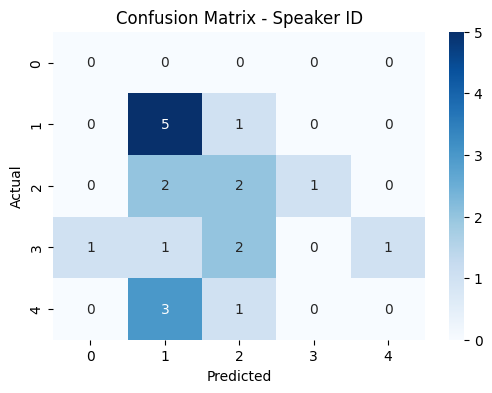

In [22]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Visualization
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d')
plt.title('Confusion Matrix - Speaker ID')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

for svm

Confusion Matrix:
 [[5 1 0 0]
 [5 0 0 0]
 [5 0 0 0]
 [3 1 0 0]]


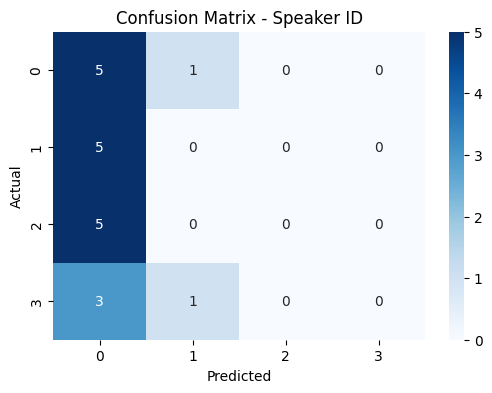

In [18]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Visualization
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d')
plt.title('Confusion Matrix - Speaker ID')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()